<a href="https://colab.research.google.com/github/mihirgohil1402-ui/Cfd-lab/blob/main/11_Convection_Diffusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 11: Convection Diffusion

**Name:** Mihir Gohil  |  **Roll No:** 23BME019  
**Course:** Computational Fluid Dynamics and Heat Transfer Lab (20ME406P), Department of Mechanical Engineering, PDEU


## 1. Aim
To solve the two-dimensional convection-diffusion equation for a passive scalar (temperature) in three prescribed velocity fields, and to compare how the Péclet number (Pe = 50, 200, 1000) changes the thermal layer, the outlet or mean temperature and the wall heat flux.

## 2. Problem and parameters
The velocity is given, so only the scalar equation is solved. Lengths are scaled with the channel height and velocities with the mean speed, so D = 1/Pe.

| Case | Velocity field | Domain | Boundary conditions |
|---|---|---|---|
| A. Forced plate | boundary-layer profile u(y), v = 0 | 3 × 1 | inlet T = 0, bottom wall T = 1, top and outlet zero gradient |
| B. Forced channel | parabolic u(y) = 6y(1 − y), v = 0 | 3 × 1 | inlet T = 0, both walls T = 1, outlet zero gradient |
| C. Recirculation | closed cell from ψ = sin(πx) sin(πy)/π | 1 × 1 | left wall T = 1, right wall T = 0, top and bottom insulated |

| Parameter | Value |
|---|---|
| Péclet numbers | 50, 200, 1000 |
| Grid A and B | 120 × 40 cells |
| Grid C | 60 × 60 cells |
| Plate boundary-layer thickness (case A) | δ = 0.4, u = U(2η − η²) for η = y/δ < 1, else U |
| Recirculating velocity (case C) | u = −sin(πx)cos(πy), v = cos(πx)sin(πy) (upward at the hot wall) |

## 3. Governing equation and method
$$\frac{\partial (uT)}{\partial x}+\frac{\partial (vT)}{\partial y} = \frac{1}{Pe}\left(\frac{\partial^2 T}{\partial x^2}+\frac{\partial^2 T}{\partial y^2}\right)$$

Cell-centred finite volume. The convective flux through each face uses the **upwind** value of T, and the diffusive flux uses the **central** difference. Face fluxes of the velocity are taken from the exact stream function (case C) or from u(y) (cases A and B) so that the discrete continuity equation is satisfied exactly. A wall on a cell face uses a half-cell distance for the diffusive flux. The resulting steady linear system is solved directly with a sparse LU factorisation.

**Quantities compared:** outlet bulk temperature (A, B), mean temperature (C), wall heat flux and the Nusselt-type number Nu = q_wall/D (heat flux relative to pure conduction across a unit temperature difference), thermal-layer thickness (height at which T falls to 1 % of the wall value at the outlet; A only; a value of 1 means the layer fills the whole domain), and the global energy balance and linear-system residual as checks. For A and B the balance is: heat entering from the hot walls = heat carried out at the outlet + heat conducted back out through the inlet face.

In [ ]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
import pandas as pd

def solve_cd(case, Pe, nx, ny):
    """Assemble and solve the steady upwind/central system. Returns fields and diagnostics."""
    Lx, Ly = (1.0, 1.0) if case == 'C' else (3.0, 1.0)
    dx, dy = Lx/nx, Ly/ny
    D = 1.0/Pe
    xc = (np.arange(nx)+0.5)*dx
    yc = (np.arange(ny)+0.5)*dy
    # --- face volumetric fluxes (per unit depth) ---
    Fe = np.zeros((nx+1, ny))      # flux through vertical faces, +x
    Fn = np.zeros((nx, ny+1))      # flux through horizontal faces, +y
    if case in ('A', 'B'):
        if case == 'A':
            eta = np.minimum(yc/0.4, 1.0)
            ucell = 2*eta - eta**2
            ucell[eta >= 1] = 1.0
        else:
            ucell = 6*yc*(1-yc)
        Fe[:, :] = (ucell*dy)[None, :]
    else:
        # psi = sin(pi x) sin(pi y)/pi, u = -dpsi/dy ... chosen so that the flow rises at x = 0
        psi = lambda X, Y: -np.sin(np.pi*X)*np.sin(np.pi*Y)/np.pi
        xf = np.linspace(0, Lx, nx+1); yf = np.linspace(0, Ly, ny+1)
        # u = dpsi/dy, v = -dpsi/dx ;  with psi above:  u = -sin(pi x)cos(pi y),  v = cos(pi x) sin(pi y)
        P = psi(xf[:, None], yf[None, :])
        Fe = P[:, 1:] - P[:, :-1]          # u*dy through vertical faces
        Fn = -(P[1:, :] - P[:-1, :])       # v*dx through horizontal faces
    # --- assemble ---
    idx = lambda i, j: i*ny + j
    rows, cols, vals = [], [], []
    b = np.zeros(nx*ny)
    for i in range(nx):
        for j in range(ny):
            k = idx(i, j)
            aP = 0.0
            # east face
            fe = Fe[i+1, j]; de = D*dy/dx
            if i < nx-1:
                # upwind convection + central diffusion
                aE = de + max(-fe, 0.0); aP += de + max(fe, 0.0)
                rows.append(k); cols.append(idx(i+1, j)); vals.append(-aE)
            else:
                if case == 'C':          # right wall: T = 0 (half-cell distance)
                    aP += 2*de + max(fe, 0.0)
                else:                    # outlet: zero gradient, outflow carries T_P
                    aP += max(fe, 0.0)
            # west face
            fw = Fe[i, j]; dw = D*dy/dx
            if i > 0:
                aW = dw + max(fw, 0.0); aP += dw + max(-fw, 0.0)
                rows.append(k); cols.append(idx(i-1, j)); vals.append(-aW)
            else:
                if case == 'C':          # left wall: T = 1
                    aP += 2*dw + max(-fw, 0.0); b[k] += 2*dw*1.0
                else:                    # inlet: T = 0, inflow carries 0, half-cell diffusion
                    aP += 2*dw + max(-fw, 0.0)
            # north face
            fn = Fn[i, j+1]; dn = D*dx/dy
            if j < ny-1:
                aN = dn + max(-fn, 0.0); aP += dn + max(fn, 0.0)
                rows.append(k); cols.append(idx(i, j+1)); vals.append(-aN)
            else:
                if case == 'B':          # top wall T = 1
                    aP += 2*dn + max(fn, 0.0); b[k] += 2*dn*1.0
                else:                    # insulated (C) or free boundary (A): zero gradient
                    aP += max(fn, 0.0)
            # south face
            fs = Fn[i, j]; ds = D*dx/dy
            if j > 0:
                aS = ds + max(fs, 0.0); aP += ds + max(-fs, 0.0)
                rows.append(k); cols.append(idx(i, j-1)); vals.append(-aS)
            else:
                if case in ('A', 'B'):   # hot bottom wall T = 1
                    aP += 2*ds + max(-fs, 0.0); b[k] += 2*ds*1.0
                else:                    # insulated
                    aP += max(-fs, 0.0)
            rows.append(k); cols.append(k); vals.append(aP)
    A = sp.csc_matrix((vals, (rows, cols)), shape=(nx*ny, nx*ny))
    T = spla.splu(A).solve(b)
    resid = np.linalg.norm(A@T - b)/np.linalg.norm(b)
    T = T.reshape(nx, ny)
    out = dict(T=T, xc=xc, yc=yc, dx=dx, dy=dy, Fe=Fe, Fn=Fn, resid=resid, D=D, case=case)
    # --- diagnostics ---
    if case in ('A', 'B'):
        uout = Fe[-1, :]/dy
        Tout = T[-1, :]
        out['bulk_out'] = np.sum(Fe[-1, :]*Tout)/np.sum(Fe[-1, :])       # flow-weighted outlet temperature
        # heat taken in through hot walls (diffusive flux, half-cell distance)
        q_bottom = np.sum(2*D*(1.0 - T[:, 0])*dx/dy)
        q_top = np.sum(2*D*(1.0 - T[:, -1])*dx/dy) if case == 'B' else 0.0
        out['q_wall'] = q_bottom + q_top
        out['q_out'] = np.sum(Fe[-1, :]*Tout)                            # convective energy leaving
        out['q_in_diff'] = np.sum(2*D*T[0, :]*dy/dx)                      # heat conducted back out through the inlet face
        out['balance_err'] = abs(out['q_wall'] - out['q_out'] - out['q_in_diff'])/max(out['q_wall'], 1e-12)
        if case == 'A':
            above = np.where(Tout < 0.01)[0]
            out['delta99'] = yc[above[0]] if len(above) else Ly
    else:
        out['T_mean'] = T.mean()
        q_left = np.sum(2*D*(1.0 - T[0, :])*dy/dx)
        q_right = np.sum(2*D*(T[-1, :] - 0.0)*dy/dx)
        out['q_wall'] = q_left
        out['balance_err'] = abs(q_left - q_right)/max(q_left, 1e-12)
        out['T_mean'] = T.mean()
    return out

## 4. Solve all nine cases

In [ ]:
Pes = (50, 200, 1000)
grid = {'A': (120, 40), 'B': (120, 40), 'C': (60, 60)}
res = {}
for case in 'ABC':
    for Pe in Pes:
        res[(case, Pe)] = solve_cd(case, Pe, *grid[case])
print("All cases solved. Largest linear-system residual:", max(r['resid'] for r in res.values()))

All cases solved. Largest linear-system residual: 7.860837401779506e-15


## 5. Temperature fields

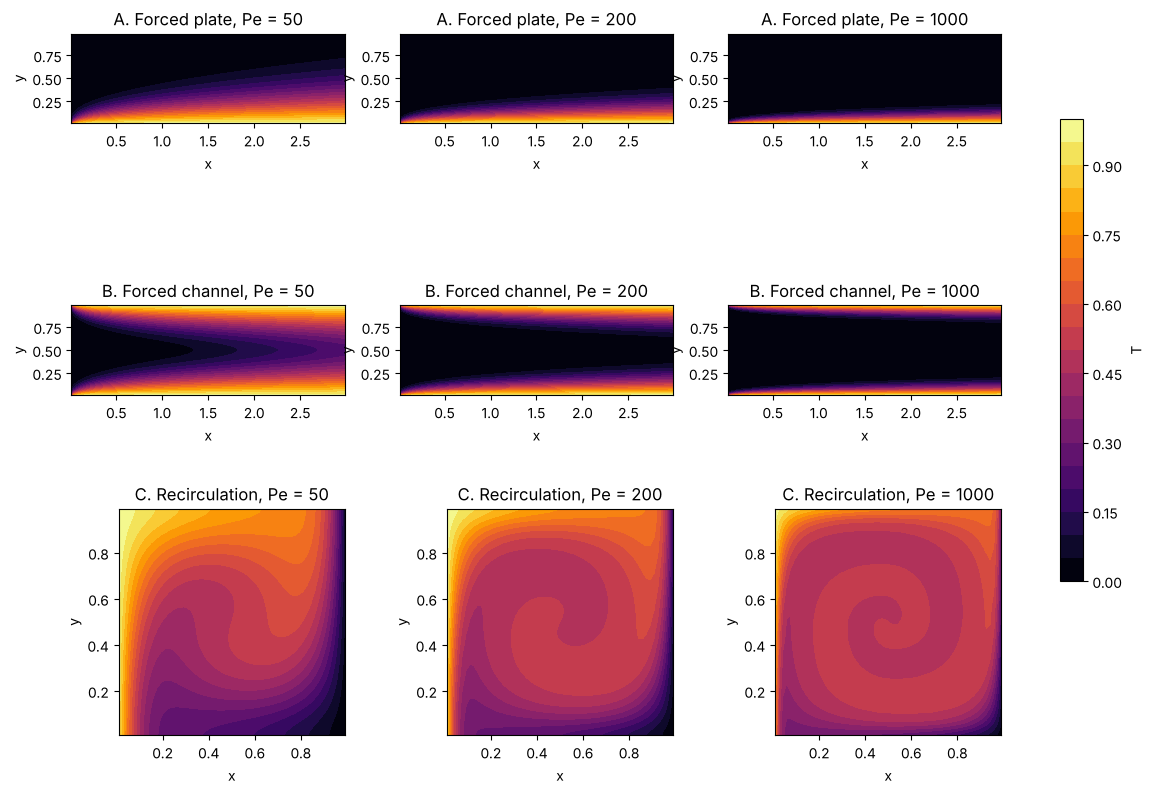

In [ ]:
titles = {'A': 'A. Forced plate', 'B': 'B. Forced channel', 'C': 'C. Recirculation'}
fig, ax = plt.subplots(3, 3, figsize=(15, 10))
for r, case in enumerate('ABC'):
    for c, Pe in enumerate(Pes):
        R = res[(case, Pe)]
        cs = ax[r, c].contourf(R['xc'], R['yc'], R['T'].T, np.linspace(0, 1, 21), cmap='inferno')
        ax[r, c].set(title=f"{titles[case]}, Pe = {Pe}", xlabel='x', ylabel='y', aspect='equal')
fig.colorbar(cs, ax=ax, shrink=0.6, label='T')
plt.show()

## 6. Outlet temperature profiles and comparison table

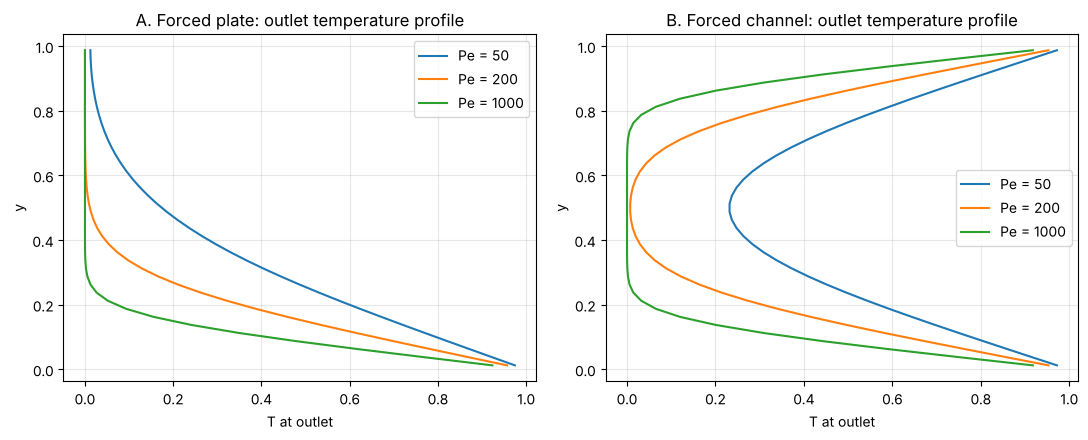

,case,Pe,outlet bulk T,mean T,thermal layer at outlet,wall heat flux,Nu = q/D,energy balance error,residual
0,A. Forced plate,50,0.219325,NaN,1.0000,0.223928,11.196394,2.398408e-14,8.365847e-16
1,A. Forced plate,200,0.091366,NaN,0.5125,0.085590,17.117946,9.090150e-15,8.920069e-16
2,A. Forced plate,1000,0.032178,NaN,0.2875,0.028698,28.697753,1.469266e-14,1.197025e-15
3,B. Forced channel,50,0.414789,NaN,NaN,0.480054,24.002689,2.344505e-14,8.753751e-16
4,B. Forced channel,200,0.170831,NaN,NaN,0.183107,36.621328,3.240054e-15,8.815270e-16
5,B. Forced channel,1000,0.059740,NaN,NaN,0.061259,61.258765,8.247607e-15,1.202495e-15
6,C. Recirculation,50,NaN,0.5,NaN,0.086870,4.343505,4.441142e-14,1.551798e-15
7,C. Recirculation,200,NaN,0.5,NaN,0.043294,8.658852,2.051492e-14,2.462955e-15
8,C. Recirculation,1000,NaN,0.5,NaN,0.019217,19.217472,1.243894e-13,7.860837e-15


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, case in zip(ax, 'AB'):
    for Pe in Pes:
        R = res[(case, Pe)]
        a.plot(R['T'][-1, :], R['yc'], label=f'Pe = {Pe}')
    a.set(title=f"{titles[case]}: outlet temperature profile", xlabel='T at outlet', ylabel='y'); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

rows = []
for case in 'ABC':
    for Pe in Pes:
        R = res[(case, Pe)]
        rows.append([titles[case], Pe,
                     R.get('bulk_out', np.nan), R.get('T_mean', np.nan), R.get('delta99', np.nan),
                     R['q_wall'], R['q_wall']*Pe, R['balance_err'], R['resid']])
pd.DataFrame(rows, columns=['case', 'Pe', 'outlet bulk T', 'mean T', 'thermal layer at outlet', 'wall heat flux', 'Nu = q/D', 'energy balance error', 'residual'])

## 7. Check of the solver: effect of grid refinement at Pe = 200

In [ ]:
rows = []
for (nx, ny) in ((60, 20), (120, 40), (240, 80)):
    R = solve_cd('B', 200, nx, ny)
    rows.append(['B. Forced channel', f'{nx} x {ny}', R['bulk_out'], R['q_wall'], R['balance_err']])
for (nx, ny) in ((30, 30), (60, 60), (120, 120)):
    R = solve_cd('C', 200, nx, ny)
    rows.append(['C. Recirculation', f'{nx} x {ny}', R['T_mean'], R['q_wall'], R['balance_err']])
pd.DataFrame(rows, columns=['case', 'grid', 'outlet bulk T (B) / mean T (C)', 'wall heat flux', 'energy balance error'])

,case,grid,outlet bulk T (B) / mean T (C),wall heat flux,energy balance error
0,B. Forced channel,60 x 20,0.171094,0.179539,3.381727e-15
1,B. Forced channel,120 x 40,0.170831,0.183107,3.240054e-15
2,B. Forced channel,240 x 80,0.170863,0.187033,3.743370e-14
3,C. Recirculation,30 x 30,0.500000,0.043527,1.976752e-14
4,C. Recirculation,60 x 60,0.500000,0.043294,2.051492e-14
5,C. Recirculation,120 x 120,0.500000,0.043030,1.670612e-13
